# Validation against tracks from Matthew Preistley

Workflow:

Validation set:
1. Define DOMAIN and REGION, define TIMERANGE that fits our data set where we conduct tracking
2. Load the validation tracks and clip to the DOMAIN.
3. Post-process the validation tracks to ensure that only storm we can detect survive in the validation dataset (using val.postprocess_validation_tracks)
4. create summary table for validaiton  

Experiment:
1. Prepare the input field ERA5 850 hPa relative vorticity (`vo`), 6-hourly, 0.25° from file slice to Dec, Jan, Feb 1998-1999 
2. Run the Hodges tracker on the domain save file for reloading.
3. Post-process the raw tracks: keep only real, mobile, long-lived cyclones (TRACK's RSPLICE filter) that affect the region.
4. Create summary table for validation
5. Compare the validation summary table to the Experiment summary table by finding candidates for each validation track (instead of using time and position of genesis I would use 60% symmetric temporal overlap and 2 degrees separation)
6. Plot candidates against each validation track
7. create confidence table with True/True, False/True, False/False and True/False (or hit & miss)
8. Plot ROC curve




In [149]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import pandas as pd
import pystormtracker as pst
from pathlib import Path
import cartopy.crs as ccrs

import sys
import os

module_dir = (Path.cwd() / ".."/".." / "algorithms").resolve()
sys.path.insert(0,str(module_dir))
import validation as val
import processing as pro
import statistics_on_tracks as sot

import importlib
importlib.reload(val)  # pick up edits in validation.py without restarting the kernel
importlib.reload(pro)  # pick up edits in processing.py without restarting the kernel
importlib.reload(sot)  # pick up edits in statistic_on_tracks.py without restarting the kernel

import importlib


## 1. Validation data file

* The validation datafile spans the winter months December, January and Jebruary of 1998 and 1999.
* The region used for tracking is the Nortern Hemisphere
* Computed by TRACK using ERA5 6 hourly $0.25\degree$ resolution vorticity field (vo).
* The vorticity is spectrally truncated to T42 and masks out wavenumbers smaller than 5
* Filtered by cyclone lifetime over 48 hours and 1000 km distance (Classic Hodges settings)
* Each cyclone must have a maximum vorticity greater than a threshold of 1*10^(-5) s^(-1).
* The MSLP minimum value is found within $5\degree$ radius using b-spline interpolation and minimization. In some instances, the method doesn't identify an MSLP minimum, so for these cases columns 5/6 are filled with 1e25 and the MSLP value is taken at the vorticity centre (columns 2,3).

The data columns are: 
1. Timestep (where 1 is the start of the season)
2. Longitude of track
3. Latitude of track
4. Vorticity value (at T42 resolution and scaled by 10**-5)
5. Longitude of MSLP minima
6. Latitude of MSLP minima
7. MSLP minima value




In [150]:
#Importing the data from the file
REGION = (-80, 20, 30, 80)   # smaller region for tracking, limited by the domain, 10 deg smaller
DOMAIN = (-90, 30, 20, 90)   # tracking domain (region + buffer), limited by the downloaded data
TIME_RANGE = ('1998-12-01 00:00:00', '1999-02-28 18:00:00')  # time range for the validation tracks

tracks_validation = val.load_tracks('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/validation_tracks_data/ERA5_19981999_TRACKS_FILTERED_pos.addmslp', start_time=TIME_RANGE[0], end_time=TIME_RANGE[1])



In [151]:
tracks_validation

,step,lon,lat,vorticity,mslp_lon,mslp_lat,mslp,track_id,time
obs,,,,,,,,,
0,1,0.487187,45.558174,2.945488,NaN,NaN,1024.025,3,1998-12-01 00:00:00
1,2,-2.346924,44.636440,2.743430,359.6110,42.38197,1017.109,3,1998-12-01 06:00:00
2,3,-7.956207,39.646866,3.258656,NaN,NaN,1017.025,3,1998-12-01 12:00:00
3,4,-9.561157,37.609779,3.978987,NaN,NaN,1012.945,3,1998-12-01 18:00:00
4,5,-9.764160,36.040455,4.625281,352.7589,35.01079,1010.072,3,1998-12-02 00:00:00
...,...,...,...,...,...,...,...,...,...
8523,351,174.133652,85.109848,3.723335,NaN,NaN,1024.317,2562,1999-02-26 12:00:00
8524,352,161.192886,84.471527,3.298671,NaN,NaN,1028.030,2562,1999-02-26 18:00:00
8525,353,150.237457,83.856377,2.820443,NaN,NaN,1031.977,2562,1999-02-27 00:00:00


<GeoAxes: title={'center': 'Tracks'}>

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


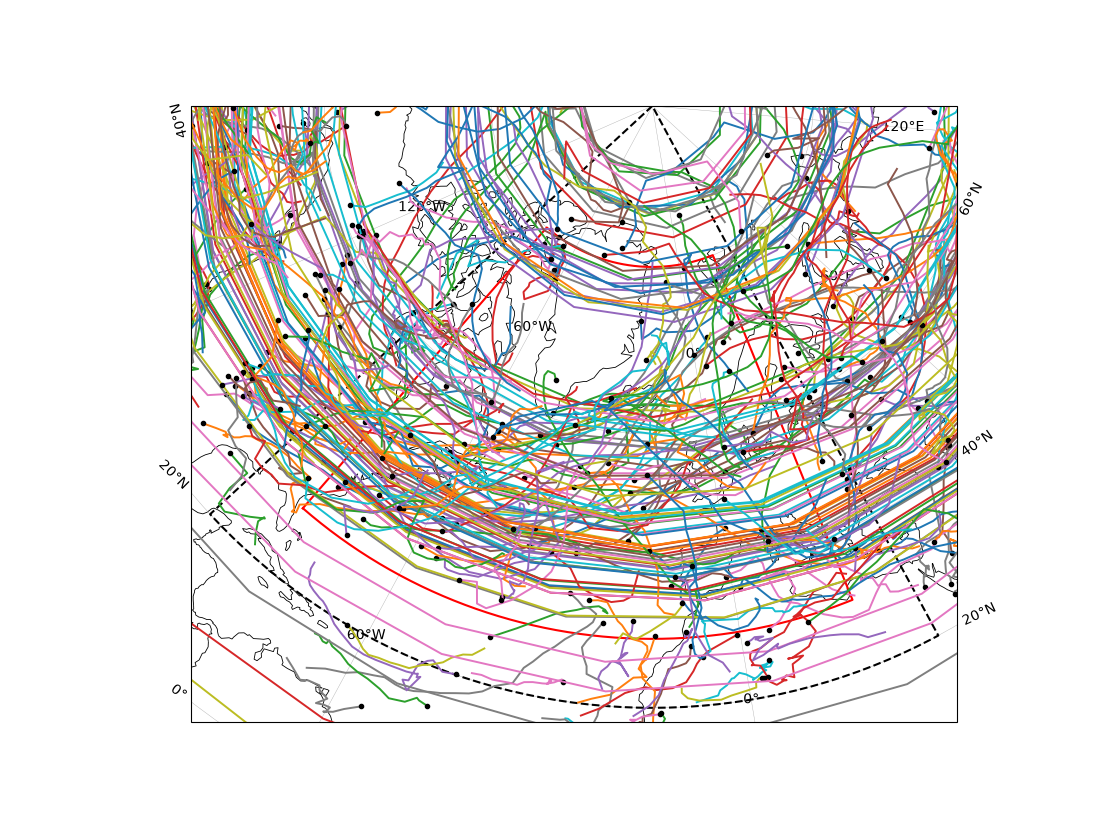

In [152]:
val.plot_regional_tracks(tracks_validation, region=REGION, domain=DOMAIN, object = False)

In [ ]:
def clip_points(df, box, time_range=None, min_points=4):
    """Keep only points inside box (lon_min, lon_max, lat_min, lat_max) and time_range;
    drop tracks with fewer than min_points left."""
    lon_min, lon_max, lat_min, lat_max = box
    mask = df["lon"].between(lon_min, lon_max) & df["lat"].between(lat_min, lat_max)
    if time_range is not None:
        mask &= df["time"].between(pd.Timestamp(time_range[0]), pd.Timestamp(time_range[1]))

    clipped = df[mask].copy()
    n_left = clipped.groupby("track_id")["track_id"].transform("size")
    return clipped[n_left >= min_points].reset_index(drop=True) #min points is the number of points within the box and time range that a track must have to be kept. If a track has less than min_points, it is dropped.




val_clipped = clip_points(tracks_validation, DOMAIN, TIME_RANGE, min_points=4)
val_clipped


,step,lon,lat,vorticity,mslp_lon,mslp_lat,mslp,track_id,time,step_km,in_region,at_edge
0,1,0.487187,45.558174,2.945488,NaN,NaN,1024.025,3,1998-12-01 00:00:00,0.000000,True,False
1,2,-2.346924,44.636440,2.743430,359.611000,42.38197,1017.109,3,1998-12-01 06:00:00,244.913948,True,False
2,3,-7.956207,39.646866,3.258656,NaN,NaN,1017.025,3,1998-12-01 12:00:00,721.918965,True,False
3,4,-9.561157,37.609779,3.978987,NaN,NaN,1012.945,3,1998-12-01 18:00:00,265.968187,True,False
4,5,-9.764160,36.040455,4.625281,352.758900,35.01079,1010.072,3,1998-12-02 00:00:00,175.433700,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
2301,343,-4.481384,87.375290,4.770901,5.318585,88.59691,1003.996,2562,1999-02-24 12:00:00,335.694235,False,False
2302,344,-13.983551,87.335152,4.309511,346.116100,89.07852,1004.317,2562,1999-02-24 18:00:00,48.902068,False,False
2303,345,-72.188629,87.176979,4.677020,292.363900,86.30700,1003.551,2562,1999-02-25 00:00:00,297.107975,False,False
2304,346,-76.903503,87.175140,4.659142,292.181600,85.84305,1004.559,2562,1999-02-25 06:00:00,25.822808,False,False


<GeoAxes: title={'center': 'Tracks'}>

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


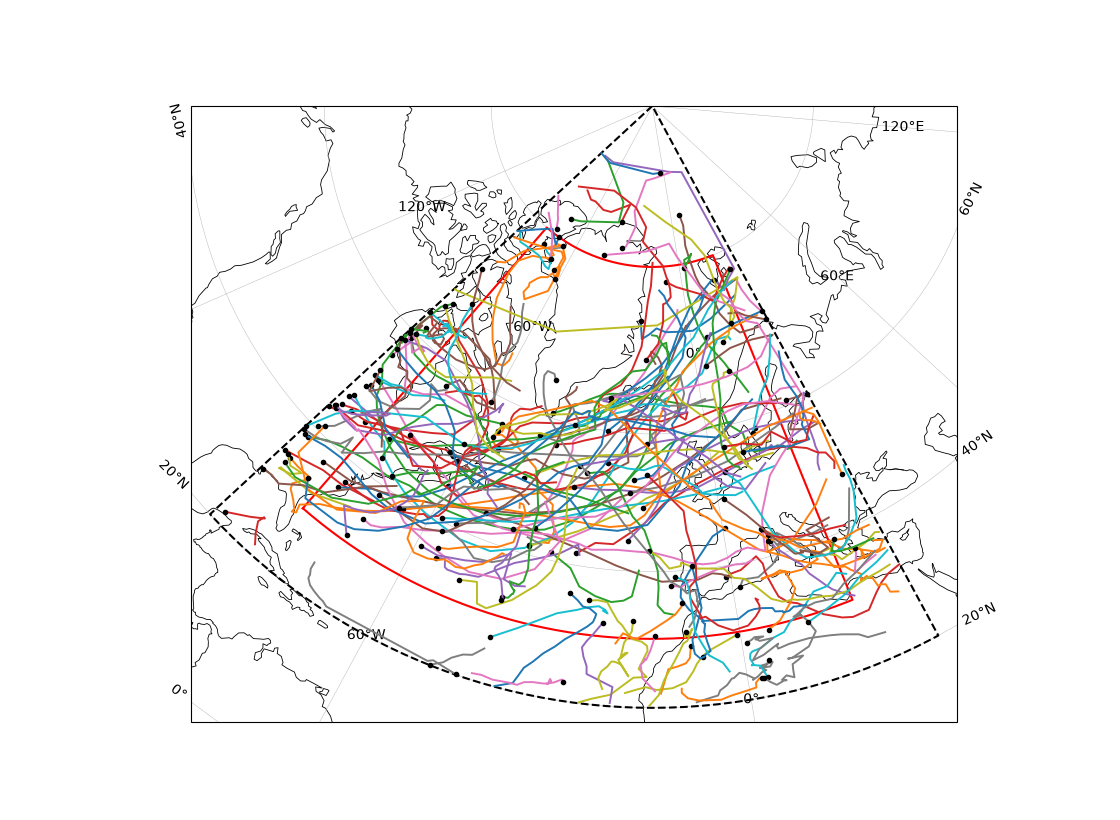

In [173]:
val.plot_regional_tracks(val_clipped, region=REGION, domain=DOMAIN, object = False)

In [154]:
tracks_val, summary_val = val.postprocess_validation_tracks(tracks_validation, region=REGION, domain=DOMAIN, time_range=TIME_RANGE,
                       region_criterion="passes", min_points_in_region=1,
                       min_peak=None, max_frac_at_edge=0.5,
                       edge_buffer_deg=2.5, drop_time_truncated=False)

In [156]:
summary_val

,track_id,n_points,start_time,end_time,lat_genesis,lon_genesis,lat_lysis,lon_lysis,path_km,n_in_region,...,lat_peak,lon_peak,peak_in_region,starts_at_first_frame,ends_at_last_frame,ok_region,ok_edge,ok_peak,ok_time,keep
0,3,8,1998-12-01 00:00:00,1998-12-02 18:00:00,45.558174,0.487187,32.335617,-6.001343,1953.201698,8,...,34.762379,-8.886871,True,True,False,True,True,True,True,True
1,7,23,1998-12-01 00:00:00,1998-12-06 12:00:00,41.390289,-39.932556,55.724674,-54.287354,3725.046847,23,...,45.770313,-36.278229,True,True,False,True,True,True,True,True
2,8,28,1998-12-01 00:00:00,1998-12-07 18:00:00,60.707550,-43.543549,54.875725,21.990213,4317.915690,26,...,65.186493,-22.897980,True,True,False,True,True,True,True,True
3,11,23,1998-12-01 00:00:00,1998-12-06 12:00:00,45.816334,-82.061401,65.929779,-95.633392,4586.956321,9,...,50.607555,-68.742401,True,True,False,True,True,True,True,True
4,20,21,1998-12-01 00:00:00,1998-12-06 00:00:00,72.899658,52.011211,81.876442,169.238129,3366.638753,0,...,73.467667,58.283115,False,True,False,False,False,True,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
462,2521,9,1999-02-26 18:00:00,1999-02-28 18:00:00,72.440567,16.541874,85.188438,-22.369354,1657.250012,5,...,72.440567,16.541874,True,False,True,True,True,True,True,True
463,2524,9,1999-02-26 18:00:00,1999-02-28 18:00:00,5.650308,63.212944,7.471993,53.195278,1180.296156,0,...,6.281818,55.973289,False,False,True,False,False,True,True,False
464,2526,8,1999-02-27 00:00:00,1999-02-28 18:00:00,39.186470,-10.691101,24.450230,-2.642365,1941.799741,5,...,37.043434,-8.124786,True,False,True,True,True,True,True,True
465,2559,14,1999-02-21 18:00:00,1999-02-25 00:00:00,31.636181,60.047581,28.794010,78.987732,2083.723805,0,...,28.358469,69.499413,False,False,False,False,False,True,True,False


/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


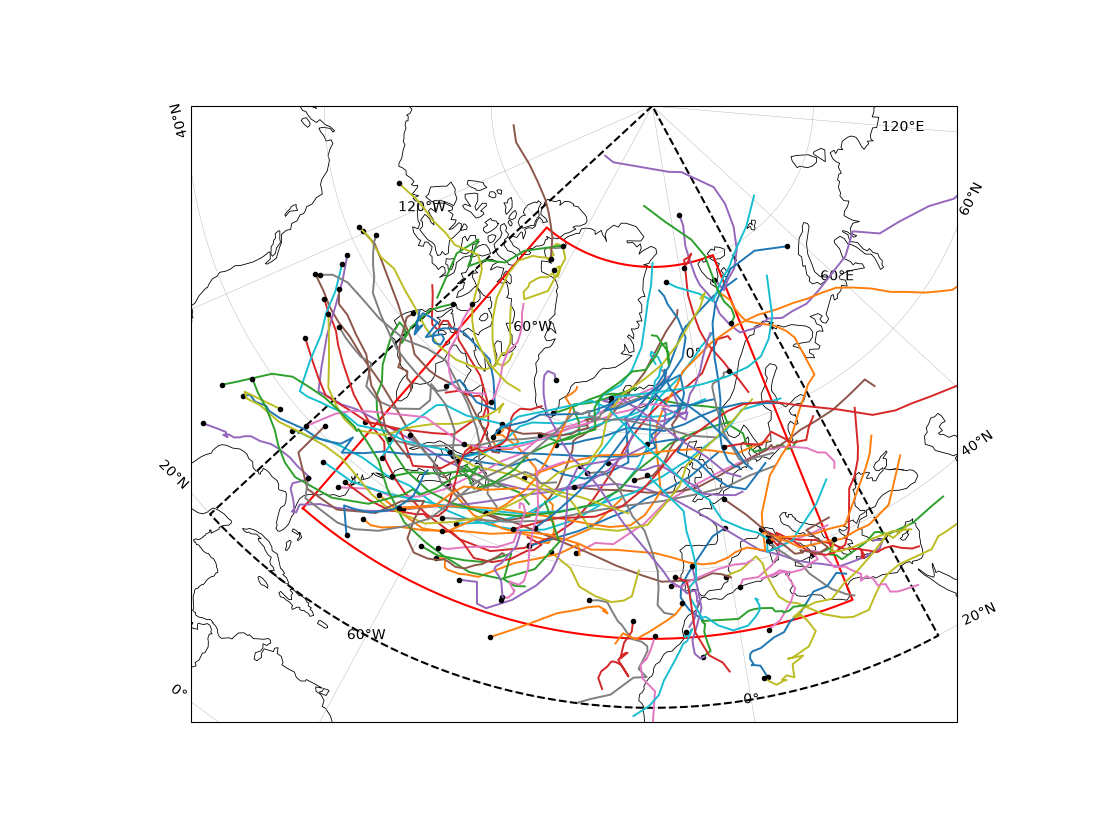

In [ ]:
ax = val.plot_regional_tracks(tracks_val, region=REGION, domain=DOMAIN, summary = summary_val, object=False)

In [174]:
tracks_val_clipped, summary_val_clipped = val.postprocess_validation_tracks(val_clipped, region=REGION, domain=DOMAIN, time_range=TIME_RANGE,
                       region_criterion="passes", min_points_in_region=1,
                       min_peak=None, max_frac_at_edge=0.5,
                       edge_buffer_deg=2.5, drop_time_truncated=False)

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


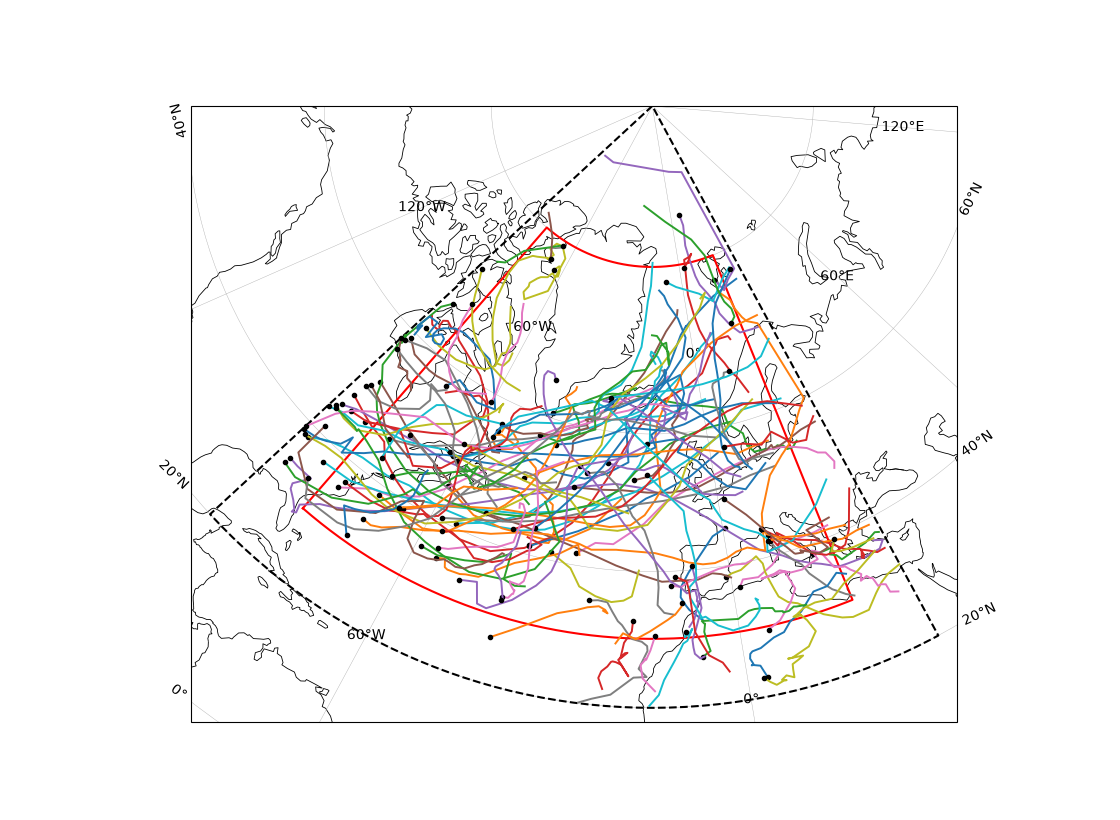

In [175]:
ax = val.plot_regional_tracks(tracks_val_clipped, region=REGION, domain=DOMAIN, summary = summary_val, object=False)

### Tracking and plotting 

In [ ]:
ds = xr.open_dataset('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/data/19981999_DJF_vo.nc')
ds

<xarray.Dataset> Size: 389MB
Dimensions:         (valid_time: 720, pressure_level: 1, latitude: 281,
                     longitude: 481)
Coordinates:
  * valid_time      (valid_time) datetime64[ns] 6kB 1998-01-01 ... 1999-12-31...
    expver          (valid_time) <U4 12kB ...
  * pressure_level  (pressure_level) float64 8B 850.0
  * latitude        (latitude) float64 2kB 90.0 89.75 89.5 ... 20.5 20.25 20.0
  * longitude       (longitude) float64 4kB -90.0 -89.75 -89.5 ... 29.75 30.0
    number          int64 8B ...
Data variables:
    vo              (valid_time, pressure_level, latitude, longitude) float32 389MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-13T09:46 GRIB to CDM+CF via cfgrib-0.9.1...

In [ ]:
ds = pro.prepare_tracking_field(ds, variable='vo',level =850, domain=DOMAIN)
ds = ds.sel(valid_time=slice(TIME_RANGE[0], TIME_RANGE[1]))
ds

<xarray.Dataset> Size: 195MB
Dimensions:     (valid_time: 360, latitude: 281, longitude: 481)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 3kB 1998-12-01 ... 1999-02-28T18:...
  * latitude    (latitude) float64 2kB 90.0 89.75 89.5 89.25 ... 20.5 20.25 20.0
  * longitude   (longitude) float64 4kB -90.0 -89.75 -89.5 ... 29.5 29.75 30.0
Data variables:
    vo          (valid_time, latitude, longitude) float32 195MB ...

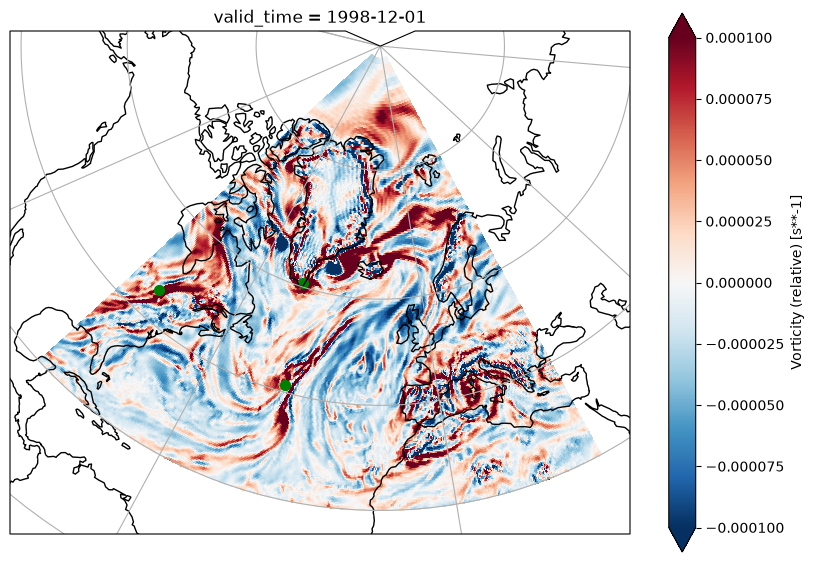

In [167]:
fig, ax = plt.subplots(figsize=(10, 7), subplot_kw=dict(projection=ccrs.LambertConformal(central_longitude=-15, central_latitude=55)))
ax.coastlines()
ax.gridlines()
ds["vo"].sel(valid_time='1998-12-01 00:00:00', method='nearest').plot(vmin=-1e-4, vmax=1e-4, cmap='RdBu_r', transform=ccrs.PlateCarree(), ax=ax)


eye_lat_7 = summary_val["lat_genesis"][summary_val["track_id"] == 7].values[0]
eye_lon_7 = summary_val["lon_genesis"][summary_val["track_id"] == 7].values[0]

eye_lat_8 = summary_val["lat_genesis"][summary_val["track_id"] == 8].values[0]
eye_lon_8 = summary_val["lon_genesis"][summary_val["track_id"] == 8].values[0]

eye_lat_11 = summary_val["lat_genesis"][summary_val["track_id"] == 11].values[0]
eye_lon_11 = summary_val["lon_genesis"][summary_val["track_id"] == 11].values[0]

ax.scatter(eye_lon_7, eye_lat_7, color='green', s=50, transform=ccrs.PlateCarree())
ax.scatter(eye_lon_8, eye_lat_8, color='green', s=50, transform=ccrs.PlateCarree())
ax.scatter(eye_lon_11, eye_lat_11, color='green', s=50, transform=ccrs.PlateCarree())

In [176]:
tracks = pro.hodges_tracker(input_file_path=ds, output_file_name='19981999_DJF_vo', track_variable='vo', min_track_points=10, taper_points=10, lmin=5,lmax=42,min_object_grid_points=18,
                    object_threshold=1e-5, exclude_boundary_extrema=False)

#tracks = pst.load_tracks('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/trackjson/19981999_DJF_vo.trackjson')

In [177]:
tracks, summary, points = pro.postprocess_tracks(tracks, region=REGION, domain=DOMAIN, time_range=TIME_RANGE,
                       region_criterion="passes", min_points_in_region=1,
                       rsplice_min_points=8, rsplice_max_points=None,
                       rsplice_distance_degrees=10.0, rsplice_distance_mode="endpoint",
                       rsplice_cadence=np.timedelta64(6, "h"),
                       min_peak=None, max_frac_at_edge=0.5,
                       edge_buffer_deg=2.5, drop_time_truncated=False)

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


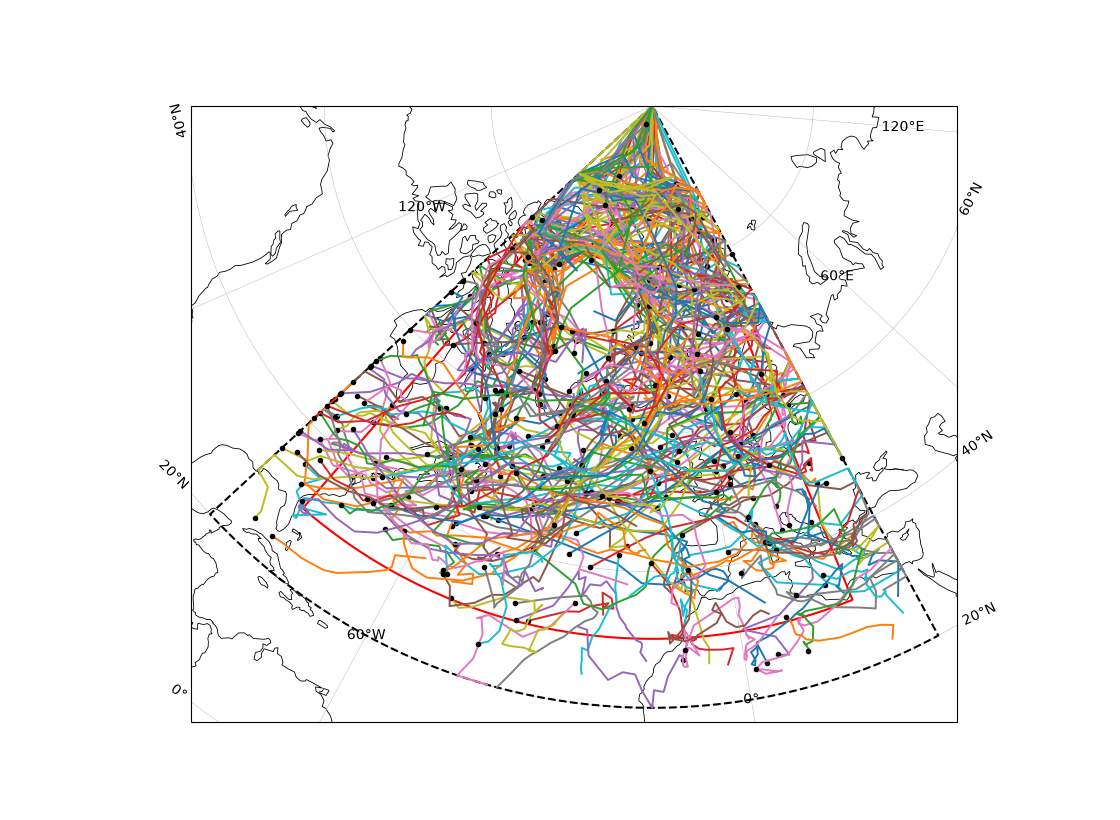

In [178]:
ax = val.plot_regional_tracks(tracks, region=REGION, domain=DOMAIN, summary = summary, object=True)


### Algorithm for comparing tracks

Specifically we want to find whether the tracks from priestley are present in our data.  

#### Pseudo-code

for track in validation_set
    record len (start, end) +- 1 day in each end (?) in time and (lat, lon) +- (5 deg?) for start and finish

same for our set, but without +-.

If our track is in BOTH recorded metrics: yes, match

else: no match



checks:

Structure:
I will create a new col in the summary of the validation pandas df.
This will contain a list of candidate tracks from our algorithm. 
Various checks will be made comparing time of genesis, genesis point, length, endpoint

First check:
sliding window of 24 hours.
Compare genisis points of these active storms if they are within 500 km save a list of track ids.


Select all tracks that are active within 24 hours.
Check the individual distances between points for these active locations
If the distance between storms are within 500 km they are the same storm


In [179]:
array_of_candidates = np.zeros(len(tracks_val.track_id.values))
array_of_candidates

array([0., 0., 0., ..., 0., 0., 0.], shape=(2024,))

In [180]:
#check if any track_ids in summary is nan:
summary

,track_id,n_points,start_time,end_time,lat_genesis,lon_genesis,lat_lysis,lon_lysis,path_km,n_in_region,...,starts_at_first_frame,ends_at_last_frame,rsplice_points,rsplice_displacement_deg,ok_rsplice,ok_region,ok_edge,ok_peak,ok_time,keep
0,1,10,1998-12-14 00:00:00,1998-12-16 06:00:00,79.50,-26.25,79.00,-34.50,3420.143276,3,...,False,False,10,1.616406,False,True,True,True,True,False
1,6,15,1998-12-14 18:00:00,1998-12-18 06:00:00,62.50,13.00,66.75,-39.50,3710.097454,15,...,False,False,15,22.189748,True,True,True,True,True,True
2,7,10,1998-12-14 00:00:00,1998-12-16 06:00:00,80.75,-84.75,81.50,-44.00,3430.868920,3,...,False,False,10,6.198256,False,True,True,True,True,False
3,8,10,1998-12-15 00:00:00,1998-12-17 06:00:00,54.25,-51.25,52.00,-22.25,2471.257060,10,...,False,False,10,17.421175,True,True,True,True,True,True
4,10,23,1998-12-11 00:00:00,1998-12-16 12:00:00,70.50,-61.25,61.00,-86.50,3136.439668,15,...,False,False,23,13.874497,True,True,True,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
482,4785,12,1999-02-21 18:00:00,1999-02-24 12:00:00,20.00,-20.00,25.00,-24.25,2041.082078,0,...,False,False,12,6.356213,False,False,True,True,True,False
483,4799,12,1999-02-22 12:00:00,1999-02-25 06:00:00,73.75,11.50,83.25,-27.00,4828.279993,1,...,False,False,12,11.724643,True,True,True,True,True,True
484,4803,10,1999-02-20 06:00:00,1999-02-22 12:00:00,71.25,21.00,75.75,-8.50,1424.400350,2,...,False,False,10,9.369333,False,True,True,True,True,False
485,4813,14,1999-02-20 06:00:00,1999-02-23 12:00:00,72.25,-53.25,76.50,-61.75,3029.920840,13,...,False,False,14,4.816682,False,True,True,True,True,False


In [181]:
summary_val.loc[0]

track_id                                   3
n_points                                   8
start_time               1998-12-01 00:00:00
end_time                 1998-12-02 18:00:00
lat_genesis                        45.558174
lon_genesis                         0.487187
lat_lysis                          32.335617
lon_lysis                          -6.001343
path_km                          1953.201698
n_in_region                                8
frac_at_edge                             0.0
duration_h                              42.0
separation_km                    1572.356627
genesis_in_region                       True
vorticity_peak                      4.645763
time_peak                1998-12-02 06:00:00
lat_peak                           34.762379
lon_peak                           -8.886871
peak_in_region                          True
starts_at_first_frame                   True
ends_at_last_frame                     False
ok_region                               True
ok_edge   

In [182]:
#creating time matching

time_window = pd.Timedelta(hours=12)

matches = []
for _, row in summary_val.iterrows():
    mask = summary["start_time"].between(row.start_time - time_window,
                                         row.start_time + time_window)
    matches.append(summary.loc[mask, "track_id"].dropna().tolist())

summary_val["matching_times_ids"] = matches




In [183]:
# creating lat/lon matching
max_distance = 500 #km
matches = []
genesis = summary.set_index("track_id")[["lat_genesis", "lon_genesis"]]
for _, row in summary_val.iterrows():
    cand = genesis.loc[row.matching_times_ids]
    dist = pro.haversine_km(row.lat_genesis, row.lon_genesis,
                            cand["lat_genesis"].values, cand["lon_genesis"].values)
    matches.append(cand.index[dist <= max_distance].tolist())

summary_val["matching_ids"] = matches
        


In [184]:
summary_val[["track_id", "matching_times_ids", "matching_ids"]]

,track_id,matching_times_ids,matching_ids
0,3,"[27, 45, 52, 369, 469, 480, 504, 626, 633, 659...",[]
1,7,"[27, 45, 52, 369, 469, 480, 504, 626, 633, 659...",[27]
2,8,"[27, 45, 52, 369, 469, 480, 504, 626, 633, 659...",[480]
3,11,"[27, 45, 52, 369, 469, 480, 504, 626, 633, 659...",[469]
4,20,"[27, 45, 52, 369, 469, 480, 504, 626, 633, 659...",[]
...,...,...,...
462,2521,[4112],[]
463,2524,[4112],[]
464,2526,[],[]
465,2559,"[4239, 4241, 4419, 4617, 4696, 4710, 4760, 4785]",[]


In [185]:
has_cands = summary_val[summary_val["matching_ids"].str.len() > 0]
has_cands[["track_id", "matching_times_ids", "matching_ids"]]


,track_id,matching_times_ids,matching_ids
1,7,"[27, 45, 52, 369, 469, 480, 504, 626, 633, 659...",[27]
2,8,"[27, 45, 52, 369, 469, 480, 504, 626, 633, 659...",[480]
3,11,"[27, 45, 52, 369, 469, 480, 504, 626, 633, 659...",[469]
12,53,"[27, 45, 52, 369, 469, 480, 504, 626, 633, 659...",[504]
30,154,"[119, 120, 126, 387, 596, 619, 667, 712, 750]",[667]
41,209,"[185, 186, 576, 602, 615, 661, 671, 687]",[671]
42,214,"[185, 186, 576, 661, 687]",[687]
48,231,"[120, 126, 596, 619, 712, 750]",[750]
66,316,"[10, 252, 259, 554, 604, 617, 773, 779]",[252]
120,631,"[913, 946, 1417, 1454, 1569]",[1569]


In [186]:
def plot_track_comparison(val_points, cand_points, val_id, cand_ids,
                          region, domain, ax=None, title=None):
    """Plot one validation track (red, thick) against its candidate tracks."""
    pc = ccrs.PlateCarree()

    # base map only: an empty frame means no tracks get drawn
    ax = val.plot_regional_tracks(val_points.iloc[:0], region, domain, ax=ax, object=False,
                              title=title or f"Track {val_id}: {len(cand_ids)} candidate(s)")

    # candidates, one colour each
    colors = plt.cm.tab10(np.linspace(0, 1, max(len(cand_ids), 1)))
    for cid, c in zip(cand_ids, colors):
        tr = cand_points[cand_points.track_id == cid]
        if tr.empty:
            continue
        ax.plot(tr.lon, tr.lat, "-", color=c, lw=1, transform=pc, label=f"cand {cid}")
        ax.plot(tr.lon.iloc[0], tr.lat.iloc[0], "o", color=c, ms=5, transform=pc)

    # validation track on top
    v = val_points[val_points.track_id == val_id]
    ax.plot(v.lon, v.lat, "-", color="red", lw=1, transform=pc, zorder=5,
            label=f"validation {val_id}")
    ax.plot(v.lon.iloc[0], v.lat.iloc[0], "*", color="red", ms=5, transform=pc, zorder=6)

    ax.legend(loc="lower left", fontsize=8)
    return ax




In [187]:
def plot_all_comparisons(val_points, cand_points, summary_with_cands,
                         region, domain, ax=None, title=None, legend=True):
    """All validation tracks with candidates (coloured) over all their candidates (grey)."""
    pc = ccrs.PlateCarree()

    val_ids = summary_with_cands["track_id"].tolist()
    cand_ids = set(i for ids in summary_with_cands["matching_ids"] for i in ids)

    ax = val.plot_regional_tracks(
        val_points.iloc[:0], region, domain, ax=ax, object=False,
        title=title or f"{len(val_ids)} validation tracks, {len(cand_ids)} candidates")

    # candidates in grey, underneath
    cands = cand_points[cand_points.track_id.isin(cand_ids)]
    for _, tr in cands.groupby("track_id"):
        ax.plot(tr.lon, tr.lat, "--", color="0.6", lw=0.8, transform=pc, zorder=1)
        ax.plot(tr.lon.iloc[0], tr.lat.iloc[0], "o", color="0.6", ms=3, transform=pc, zorder=1)

    # validation tracks in colour, on top
    vals = val_points[val_points.track_id.isin(val_ids)]
    colors = plt.cm.tab20(np.linspace(0, 1, max(len(val_ids), 1)))
    for (vid, tr), c in zip(vals.groupby("track_id"), colors):
        ax.plot(tr.lon, tr.lat, "-", color=c, lw=1.5, transform=pc, zorder=5,
                label=f"val {vid}")
        ax.plot(tr.lon.iloc[0], tr.lat.iloc[0], "*", color=c, ms=8, transform=pc, zorder=6)

    # a single legend entry for the grey candidates
    ax.plot([], [], "-", color="0.6", label="candidates")
    if legend:
        ax.legend(loc="lower left", fontsize=7, ncol=2)
    return ax

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


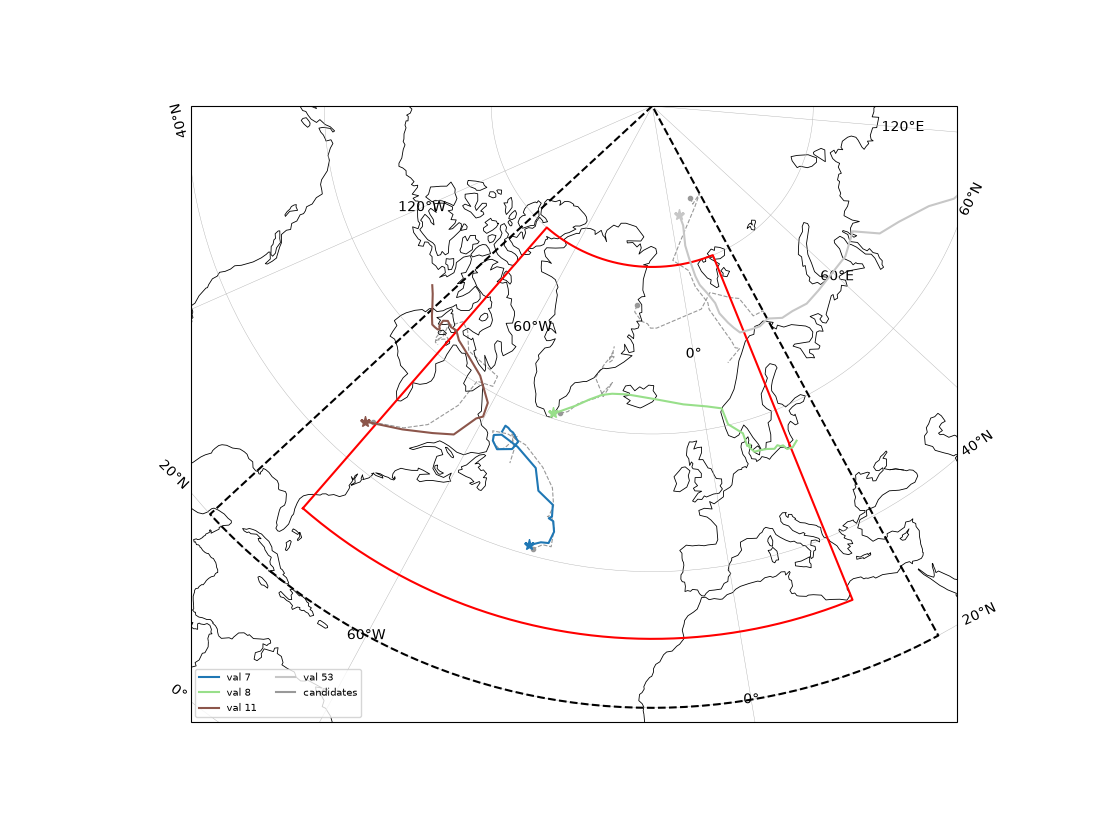

In [188]:
has_cands = summary_val[summary_val["matching_ids"].str.len() > 0]
has_cands=has_cands.iloc[:5]
plot_all_comparisons(tracks_val, points, has_cands, region=REGION, domain=DOMAIN)
plt.show()